# Опоздания доставок: решение для руководителя

In [1]:
import sys
import math
import numpy as np
import matplotlib
from pathlib import Path

import pandas as pd

def data_folder(*files):
    for folder in (Path("data"), Path("../data")):
        if all((folder / filename).is_file() for filename in files):
            print("Папка данных:", folder.resolve())
            return folder
    raise FileNotFoundError("В data/ и ../data/ нет полного набора: " + ", ".join(files))

print("Python", sys.version.split()[0], "| pandas", pd.__version__)
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

DELIVERIES_FILE = "deliveries.csv"
DATA = data_folder(DELIVERIES_FILE)
raw = pd.read_csv(DATA / DELIVERIES_FILE, parse_dates=["created"])
RANDOM_STATE=42
FIGURES=Path('figures-'+Path(DELIVERIES_FILE).stem)
FIGURES.mkdir(exist_ok=True)
def say(text):
    display(Markdown('**Вывод.** '+text))
def save(fig,name):
    fig.tight_layout()
    fig.savefig(FIGURES/(name+'.png'),dpi=130,bbox_inches='tight')
    plt.show()
def prepare(raw):
    t=raw[raw.actual_min.between(1,299)].copy()
    t['late']=t.actual_min>t.promised_min
    t['delay']=t.actual_min-t.promised_min
    t['hour']=t.created.dt.hour
    return t
def delivery_report(raw):
    t=prepare(raw)
    if t.empty:
        return dict(late_pct=None,worst_courier=None,worst_shop=None,peak_hours=[],fair_promise=None)
    chosen=t.groupby('courier').late.mean().sort_index().idxmax()
    s=t[(t.courier==chosen)&(t.promised_min==30)].actual_min
    h=t.groupby('hour').late.agg(['mean','size'])
    return dict(late_pct=round(t.late.mean()*100,1),worst_courier=chosen,worst_shop=t.groupby('shop_id').late.mean().sort_index().idxmax(),peak_hours=h[(h['size']>=50)&(h['mean']>.25)].index.tolist(),fair_promise=None if s.empty else math.ceil(s.quantile(.8)/5)*5)
ok=prepare(raw)
report=delivery_report(raw)
chosen=report['worst_courier']
period=f'{raw.created.min():%d.%m.%Y}–{raw.created.max():%d.%m.%Y}'
context=f'{DELIVERIES_FILE}; {period}'


Python 3.12.14 | pandas 3.0.6
Папка данных: /private/tmp/kuch04round/student-retest/data


## Цель и главное
Выбрать подгруппу для пилота честного обещания и проверить, можно ли уменьшить опоздания. Доля рассчитывается по пригодному фактическому времени. Обещание не меняет время поездки; экономика решения требует отдельного наблюдения.

In [2]:
g=ok[ok.courier==chosen]
s30=g[g.promised_min==30]
pilot_original=int(g.promised_min.mode().iloc[0])
pilot=g[g.promised_min==pilot_original]
pilot_promise=math.ceil(pilot.actual_min.quantile(.8)/5)*5
excluded=len(raw)-len(ok)
lower=ok.late.sum()/len(raw)*100
upper=(ok.late.sum()+excluded)/len(raw)*100
say(f'{context}. Опоздали {ok.late.sum()}/{len(ok)} пригодных доставок ({ok.late.mean():.1%}); неизвестны статусы {excluded}/{len(raw)}. Для всех {len(raw)} доставок крайние сценарии {lower:.1f}–{upper:.1f}%. Наибольшая доля у {chosen}: {g.late.sum()}/{len(g)} ({g.late.mean():.1%}). При одинаковом обещании 30 мин в этой группе {s30.late.sum()}/{len(s30)} ({s30.late.mean():.1%}); кандидат срока по п80 этой подгруппы {report["fair_promise"]} мин. Это результат текущей выгрузки, не причинная оценка работы курьеров.')
say(f'Предлагаемый пилот в этой выгрузке: {chosen}, исходное обещание {pilot_original} мин → {pilot_promise} мин; уложились бы {(pilot.actual_min<=pilot_promise).sum()}/{len(pilot)} ({(pilot.actual_min<=pilot_promise).mean():.1%}). Цель ≥80%, с контролем конверсии и маржи на каждого гостя, увидевшего срок. Если цель не достигнута или маржа падает, не масштабировать. Расчёт для 30 минут выше и эта собственная подгруппа могут различаться.')
display(ok.groupby(['promised_min','courier']).late.agg(опоздали='sum',доставок='size',доля='mean').round(3))

**Вывод.** deliveries.csv; 01.09.2026–30.11.2026. Опоздали 441/1841 пригодных доставок (24.0%); неизвестны статусы 36/1877. Для всех 1877 доставок крайние сценарии 23.5–25.4%. Наибольшая доля у пеший: 298/403 (73.9%). При одинаковом обещании 30 мин в этой группе 221/317 (69.7%); кандидат срока по п80 этой подгруппы 40 мин. Это результат текущей выгрузки, не причинная оценка работы курьеров.

**Вывод.** Предлагаемый пилот в этой выгрузке: пеший, исходное обещание 30 мин → 40 мин; уложились бы 258/317 (81.4%). Цель ≥80%, с контролем конверсии и маржи на каждого гостя, увидевшего срок. Если цель не достигнута или маржа падает, не масштабировать. Расчёт для 30 минут выше и эта собственная подгруппа могут различаться.

опоздали  доставок   доля
promised_min courier                           
30           авто           18       102  0.176
             вело           58       238  0.244
             пеший         221       317  0.697
45           авто            4       278  0.014
             вело           46       592  0.078
             пеший          77        86  0.895
60           авто            8       186  0.043
             вело            9        42  0.214

**Вывод по главному.** Выбранная группа и числа вычислены из текущего файла. Пилот ниже задаёт подгруппу явно; разные исходные обещания нельзя смешать в одно обещание.

## Данные и предобработка
Одна строка — доставка. Время вне 1–299 и пропуски исключены из расчёта основной доли; их статус остаётся неизвестным. При смене выгрузки применимость этого диапазона надо подтвердить заново.

In [3]:
log={'всего':len(raw),'без времени':int(raw.actual_min.isna().sum()),'невозможное время':int((raw.actual_min.notna()&~raw.actual_min.between(1,299)).sum()),'осталось':len(ok)}
display(pd.Series(log,name='доставок').to_frame())
print('Полные дубли:',raw.duplicated().sum())
loss=raw[~raw.index.isin(ok.index)].groupby('courier').size()
quality=pd.DataFrame({'опоздали':ok.groupby('courier').late.sum(),'все':raw.groupby('courier').size(),'неизвестно':loss}).fillna(0)
quality['нижняя_%']=quality['опоздали']/quality['все']*100
quality['верхняя_%']=(quality['опоздали']+quality['неизвестно'])/quality['все']*100
display(quality.round(1))
say(f'{context}. Пригодны {len(ok)}/{len(raw)}. Границы {lower:.1f}–{upper:.1f}% — сценарии неизвестных статусов, не доверительный интервал. Оценок {ok.rating.notna().sum()}/{len(ok)}; отсутствие отзыва не заменяю оценкой.')

,доставок
всего,1877
без времени,25
невозможное время,11
осталось,1841


Полные дубли: 0


,опоздали,все,неизвестно,нижняя_%,верхняя_%
courier,,,,,
авто,30,581,15,5.2,7.7
вело,113,888,16,12.7,14.5
пеший,298,408,5,73.0,74.3


**Вывод.** deliveries.csv; 01.09.2026–30.11.2026. Пригодны 1841/1877. Границы 23.5–25.4% — сценарии неизвестных статусов, не доверительный интервал. Оценок 1034/1841; отсутствие отзыва не заменяю оценкой.

**Вывод о качестве.** Доля среди пригодных и пределы всей выгрузки отвечают на разные вопросы. Таблица показывает возможную концентрацию исключений по типам.

## Масштаб и сравнение групп
### 1. Масштаб задержек

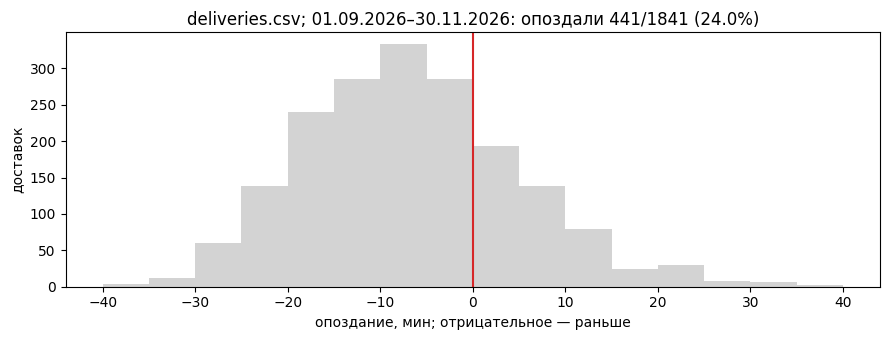

**Вывод.** Среди 441 опоздавших медиана задержки 7.0 мин, п90 20.0 мин. Вне окна −40…40: 2/1841 доставок. Ни квантиль, ни крайний сценарий не обещают будущее качество.

In [4]:
late_pct=round(ok.late.mean()*100,1)
late_median=ok.loc[ok.late,'delay'].median();p90_late=ok.loc[ok.late,'delay'].quantile(.9)
fig,ax=plt.subplots(figsize=(9,3.5))
ax.hist(ok.delay,bins=16,range=(-40,40),color='lightgray');ax.axvline(0,color='tab:red')
ax.set(title=f'{context}: опоздали {ok.late.sum()}/{len(ok)} ({late_pct}%)',xlabel='опоздание, мин; отрицательное — раньше',ylabel='доставок')
save(fig,'scale')
say(f'Среди {ok.late.sum()} опоздавших медиана задержки {late_median:.1f} мин, п90 {p90_late:.1f} мин. Вне окна −40…40: {((ok.delay < -40)|(ok.delay>40)).sum()}/{len(ok)} доставок. Ни квантиль, ни крайний сценарий не обещают будущее качество.')

**Вывод по масштабу.** Сравнивать сроки надо с обещанием конкретной доставки, а не со средним фактом всей сети.

### 2. Факторы и одинаковое обещание

courier    68.6
items      22.3
hour       20.9
weather    15.0
shop_id    13.1
dtype: float64

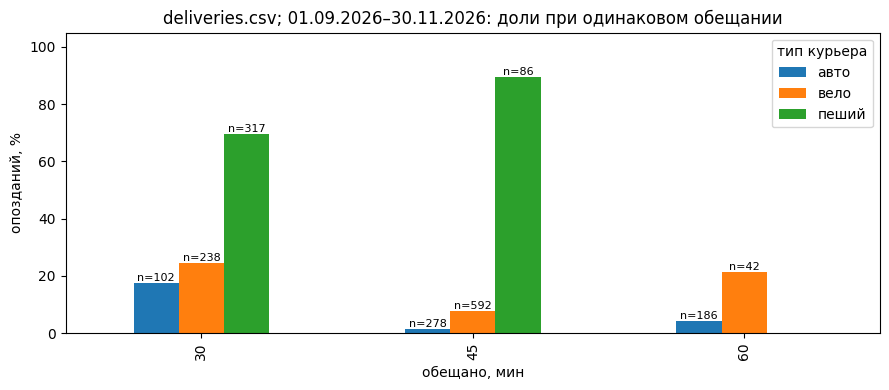

**Вывод.** Размах максимален у courier: 68.6 п.п. Самая высокая общая доля у пеший; разница при одинаковом обещании видна в таблице первого раздела. Маршруты, часы и состав ещё не уравнены. Размер групп и число категорий меняют размах.

In [5]:
r={}
for col in ['courier','weather','shop_id','items','hour']:
    a=ok.groupby(col).late.agg(['mean','size'])
    s=a[a['size']>=50]['mean']
    r[col]=round((s.max()-s.min())*100,1)
ranking=pd.Series(r).sort_values(ascending=False);top_factor=ranking.index[0]
display(ranking)
pv=ok.pivot_table(index='promised_min',columns='courier',values='late',aggfunc='mean')*100
counts=ok.pivot_table(index='promised_min',columns='courier',values='late',aggfunc='size')
fig,ax=plt.subplots(figsize=(9,4));pv.plot(kind='bar',ax=ax)
ax.set(title=f'{context}: доли при одинаковом обещании',xlabel='обещано, мин',ylabel='опозданий, %',ylim=(0,105))
for container,col in zip(ax.containers,pv.columns):
    ax.bar_label(container,labels=[f'n={v:.0f}' if pd.notna(v) else '' for v in counts[col]],fontsize=8)
ax.legend(title='тип курьера');save(fig,'promise')
say(f'Размах максимален у {top_factor}: {ranking.iloc[0]:.1f} п.п. Самая высокая общая доля у {chosen}; разница при одинаковом обещании видна в таблице первого раздела. Маршруты, часы и состав ещё не уравнены. Размер групп и число категорий меняют размах.')

**Вывод по факторам.** Общая доля помогает выбрать, с чего начать; сравнение при одном обещании убирает только одно различие.

### 3. Два вопроса о новом сроке
Общий отчёт всегда считает худшую группу с обещанием 30 минут. Отдельное исследование берёт наиболее частое обещание выбранной группы; это может оказаться 45 минут. Эти пороги нельзя взаимозаменять.

In [6]:
walk_p80=s30.actual_min.quantile(.8)
fair_promise=report['fair_promise']
if fair_promise is None:
    say(f'{context}: у {chosen} нет подгруппы с обещанием 30 минут — fair_promise=None.')
else:
    say(f'{context}: отчёт, {chosen}, исходное обещание 30 мин, п80 {walk_p80:.1f}, кандидат {fair_promise} мин; уложились бы {(s30.actual_min<=fair_promise).sum()}/{len(s30)} ({(s30.actual_min<=fair_promise).mean():.1%}).')
pilot_original=int(g.promised_min.mode().iloc[0])
pilot=g[g.promised_min==pilot_original]
pilot_p80=pilot.actual_min.quantile(.8)
pilot_promise=math.ceil(pilot_p80/5)*5
other=ok[(ok.courier!=chosen)&(ok.promised_min==pilot_original)]
s45=g[g.promised_min==45]
walk45_km=s45.distance_km.median();walk45_min=s45.actual_min.median()
say(f'Собственная подгруппа пилота: {chosen}, обещали {pilot_original} мин; опоздали {pilot.late.sum()}/{len(pilot)} ({pilot.late.mean():.1%}), остальные курьеры с тем же обещанием {other.late.sum()}/{len(other)} ({other.late.mean():.1%}). П80 факта {pilot_p80:.1f} мин, кандидат {pilot_promise} мин: уложились бы {(pilot.actual_min<=pilot_promise).sum()}/{len(pilot)} ({(pilot.actual_min<=pilot_promise).mean():.1%}). При обещании 45 мин у {chosen} медианы расстояния {walk45_km:.1f} км и факта {walk45_min:.1f} мин (n={len(s45)}).')

**Вывод.** deliveries.csv; 01.09.2026–30.11.2026: отчёт, пеший, исходное обещание 30 мин, п80 40.0, кандидат 40 мин; уложились бы 258/317 (81.4%).

**Вывод.** Собственная подгруппа пилота: пеший, обещали 30 мин; опоздали 221/317 (69.7%), остальные курьеры с тем же обещанием 76/340 (22.4%). П80 факта 40.0 мин, кандидат 40 мин: уложились бы 258/317 (81.4%). При обещании 45 мин у пеший медианы расстояния 3.0 км и факта 59.5 мин (n=86).

**Вывод по сроку.** Это пересчёт на исходных маршрутах. Смена обещания может поменять спрос и состав маршрутов; для нового спроса п80 не гарантирован.

### 4. KZN-2 внутри курьеров

In [7]:
ok['kzn2']=ok.shop_id=='KZN-2'
a=ok.groupby(['courier','kzn2']).actual_min.median().unstack()
b=ok.groupby(['courier','kzn2']).distance_km.median().unstack()
kzn2_gap=(a[True]-a[False]).to_dict();same_distance=(b[True]-b[False]).round(1).to_dict()
display(pd.DataFrame({'разница времени, мин':kzn2_gap,'разница расстояния, км':same_distance}))
display(ok.groupby(['courier','kzn2']).size())
say(f'{context}. Разница медиан KZN-2 минус остальные: {kzn2_gap}; расстояния {same_distance}. Состав курьеров учтён, условия внутри них ещё различаются.')

,"разница времени, мин","разница расстояния, км"
авто,6.0,0.1
вело,4.0,-0.1
пеший,4.5,0.0


courier  kzn2 
авто     False    483
         True      83
вело     False    743
         True     129
пеший    False    343
         True      60
dtype: int64

**Вывод.** deliveries.csv; 01.09.2026–30.11.2026. Разница медиан KZN-2 минус остальные: {'авто': 6.0, 'вело': 4.0, 'пеший': 4.5}; расстояния {'авто': 0.1, 'вело': -0.1, 'пеший': 0.0}. Состав курьеров учтён, условия внутри них ещё различаются.

**Вывод по KZN-2.** Разницы не доказывают причину задержки в кофейне. Запросить этапы сборки, ожидания и поездки.

### 5. Недели и снег

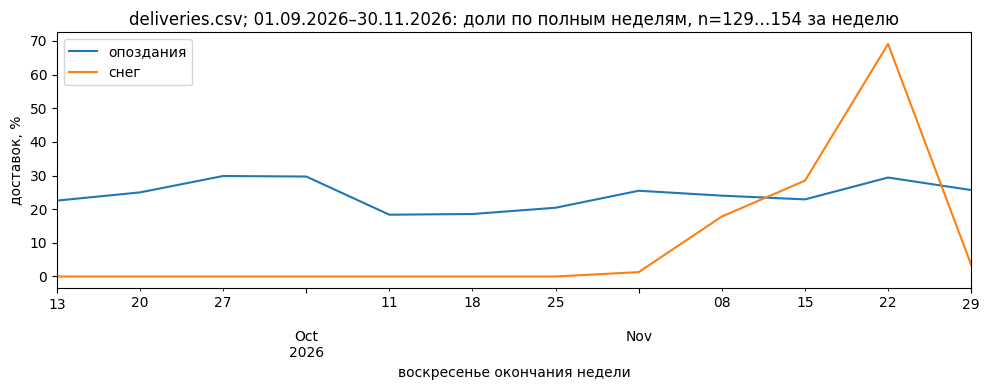

,late_pct,snow_pct,доставок
created,,,
2026-09-13,22.6,0.0,133
2026-09-20,25.0,0.0,132
2026-09-27,29.9,0.0,154
2026-10-04,29.7,0.0,138
2026-10-11,18.4,0.0,147
2026-10-18,18.6,0.0,140
2026-10-25,20.4,0.0,137
2026-11-01,25.5,1.3,153
2026-11-08,24.0,17.8,129


**Вывод.** Корреляция недельных долей 0.34; недель 12. Первая и последняя неполные исключены; снег совпадает с ноябрём, поэтому календарные изменения остаются альтернативой.

In [8]:
ok['snow']=ok.weather=='снег'
weeks=ok.set_index('created').resample('W')[['late','snow']].mean().iloc[1:-1]*100
weeks.columns=['late_pct','snow_pct'];r_weeks=round(weeks.late_pct.corr(weeks.snow_pct),2)
weekly_n=ok.set_index('created').resample('W').size().iloc[1:-1]
fig,ax=plt.subplots(figsize=(10,4));weeks.rename(columns={'late_pct':'опоздания','snow_pct':'снег'}).plot(ax=ax)
ax.set(title=f'{context}: доли по полным неделям, n={weekly_n.min()}…{weekly_n.max()} за неделю',xlabel='воскресенье окончания недели',ylabel='доставок, %')
save(fig,'weeks')
display(pd.concat([weeks,weekly_n.rename('доставок')],axis=1).round(1))
say(f'Корреляция недельных долей {r_weeks}; недель {len(weeks)}. Первая и последняя неполные исключены; снег совпадает с ноябрём, поэтому календарные изменения остаются альтернативой.')

**Вывод по неделям.** График описывает совместную динамику, а не причинный эффект погоды.

### 6. Отзывы

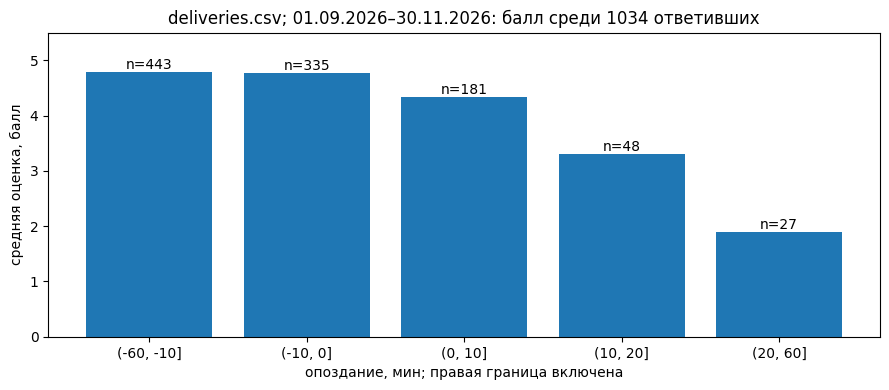

**Вывод.** Вовремя средняя оценка 4.77; при задержке >10 мин 2.8, n=75 полученных оценок, доля ≤3: 53/75 (70.7%). Среди всех пригодных задержка >10 мин: 130/1841 (7.1%). Одинаковая частота отклика не гарантирует одинаковый состав ответивших; на всех гостей средние не переношу.

In [9]:
rating_on_time=round(ok.loc[~ok.late,'rating'].mean(),2)
s=ok.loc[ok.delay>10,'rating'].dropna();rating_late10=round(s.mean(),2);low_share_late10=round((s<=3).mean()*100,1)
t=ok.groupby(pd.cut(ok.delay,[-60,-10,0,10,20,60]),observed=False).rating.agg(rating='mean',n='count')
fig,ax=plt.subplots(figsize=(9,4));bars=ax.bar(t.index.astype(str),t.rating)
ax.bar_label(bars,labels=[f'n={v}' for v in t.n]);ax.set(title=f'{context}: балл среди {ok.rating.notna().sum()} ответивших',xlabel='опоздание, мин; правая граница включена',ylabel='средняя оценка, балл',ylim=(0,5.5))
save(fig,'ratings')
say(f'Вовремя средняя оценка {rating_on_time}; при задержке >10 мин {rating_late10}, n={len(s)} полученных оценок, доля ≤3: {(s<=3).sum()}/{len(s)} ({low_share_late10}%). Среди всех пригодных задержка >10 мин: {(ok.delay>10).sum()}/{len(ok)} ({(ok.delay>10).mean():.1%}). Одинаковая частота отклика не гарантирует одинаковый состав ответивших; на всех гостей средние не переношу.')

**Вывод по отзывам.** Отзывы и задержки могут иметь общие причины; дополнительная метрика delay>10 относится ко всем пригодным доставкам независимо от отзыва.

## Две собственные находки
Сохраняю исходные условия items>=5 и distance<=2. Проверяю пороги n>=50 в обеих группах и разницу не менее 5 п.п. Заранее выбранное условие может не пройти на новом составе — не подменяю его другим.

**Вывод.** deliveries.csv; 01.09.2026–30.11.2026; items >= 5: 86/225 (38.2%) против 355/1616 (22.0%). Разница 16.3 п.п.; условия находки выполнены: True.

опоздали  доставок   доля
courier inside                           
авто    False         21       492  0.043
        True           9        74  0.122
вело    False         88       777  0.113
        True          25        95  0.263
пеший   False        246       347  0.709
        True          52        56  0.929

**Вывод.** deliveries.csv; 01.09.2026–30.11.2026; distance_km <= 2: 297/681 (43.6%) против 144/1160 (12.4%). Разница 31.2 п.п.; условия находки выполнены: True.

опоздали  доставок   доля
courier inside                           
авто    False         12       460  0.026
        True          18       106  0.170
вело    False         55       615  0.089
        True          58       257  0.226
пеший   False         77        85  0.906
        True         221       318  0.695

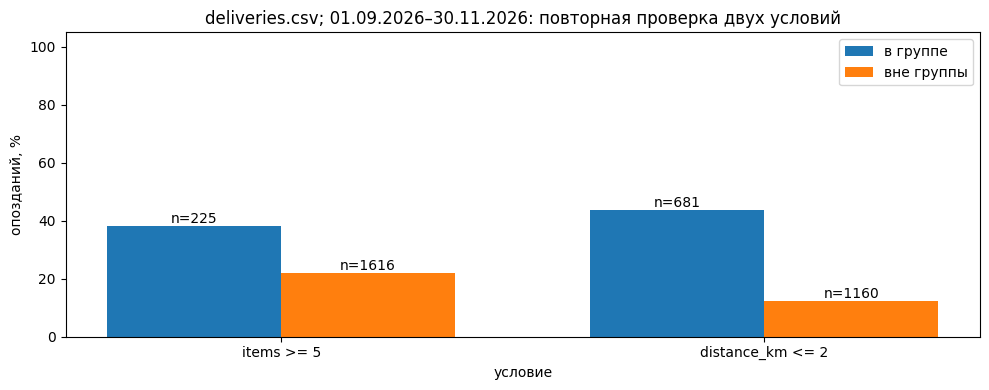

**Вывод.** Доля по коротким маршрутам неоднородна внутри типов курьера. Сравнение общей доли не изолирует расстояние: различаются обещания и распределение курьеров. Для размера заказа также остаются время, погода и состав. Если условия зачёта не выполнены, исходная находка на новом составе не подтверждается.

In [10]:
findings=[]
for condition in ['items >= 5','distance_km <= 2']:
    a=ok.query(condition);b=ok.drop(a.index)
    x=a.late.mean()*100;y=b.late.mean()*100
    valid=len(a)>=50 and len(b)>=50 and abs(x-y)>=5
    findings.append({'группа':condition,'n':len(a),'late_pct':round(x,1),'остальные_pct':round(y,1),'valid':valid,'вывод':f'{condition}: {a.late.sum()}/{len(a)} против {b.late.sum()}/{len(b)}; условия зачёта {valid}'})
    say(f'{context}; {condition}: {a.late.sum()}/{len(a)} ({x:.1f}%) против {b.late.sum()}/{len(b)} ({y:.1f}%). Разница {x-y:.1f} п.п.; условия находки выполнены: {valid}.')
    display(ok.assign(inside=ok.index.isin(a.index)).groupby(['courier','inside']).late.agg(опоздали='sum',доставок='size',доля='mean').round(3))
fig,ax=plt.subplots(figsize=(10,4));x=np.arange(2)
a=ax.bar(x-.18,[f['late_pct'] for f in findings],width=.36,label='в группе')
b=ax.bar(x+.18,[f['остальные_pct'] for f in findings],width=.36,label='вне группы')
ax.bar_label(a,labels=[f'n={f["n"]}' for f in findings]);ax.bar_label(b,labels=[f'n={len(ok)-f["n"]}' for f in findings])
ax.set_xticks(x);ax.set_xticklabels([f['группа'] for f in findings]);ax.legend()
ax.set(title=f'{context}: повторная проверка двух условий',xlabel='условие',ylabel='опозданий, %',ylim=(0,105));save(fig,'own')
say('Доля по коротким маршрутам неоднородна внутри типов курьера. Сравнение общей доли не изолирует расстояние: различаются обещания и распределение курьеров. Для размера заказа также остаются время, погода и состав. Если условия зачёта не выполнены, исходная находка на новом составе не подтверждается.')

**Вывод по находкам.** Направление и пригодность результата определяются текущими вычислениями выше. Два разных признака ещё не означают два независимых причинных механизма.

## Выводы и рекомендации
Действие, пределы переносимости и условие отказа.

In [11]:
say(f'{context}. Предлагаю контролируемый пилот для {chosen} с исходным обещанием {pilot_original} мин: кандидат {pilot_promise} мин; исходная опора {(pilot.actual_min<=pilot_promise).sum()}/{len(pilot)} ({(pilot.actual_min<=pilot_promise).mean():.1%}). Требовать не менее 80% своевременных доставок на сопоставимых маршрутах и контролировать конверсию, отказы и маржу. Если своевременность ниже 80%, либо маржа падает из-за отказов, отказаться от масштабирования срока. Для реального ускорения отдельно проверить перераспределение нагрузки в случайно выбранных сопоставимых сменах и сравнить факт времени/задержек с контролем; если факт не улучшается либо ухудшаются другие группы, отказаться от перераспределения. Изменение названия обещания само по себе не ускоряет доставку.')
failed=[f['группа'] for f in findings if not f['valid']]
say(f'Не прошли прежние пороги собственных находок на этой выгрузке: {failed or "нет"}. Границы неизвестных статусов и добровольный отбор отзывов остаются. Порог времени 1–299 и п80 требуют проверки для нового процесса. fair_promise общего отчёта = {report["fair_promise"]} мин для {chosen}/30; собственный кандидат {pilot_promise} мин для {chosen}/{pilot_original}. Период и подгруппа обязательны рядом с числом.')
print('Пустой период:',delivery_report(raw.iloc[:0]))

**Вывод.** deliveries.csv; 01.09.2026–30.11.2026. Предлагаю контролируемый пилот для пеший с исходным обещанием 30 мин: кандидат 40 мин; исходная опора 258/317 (81.4%). Требовать не менее 80% своевременных доставок на сопоставимых маршрутах и контролировать конверсию, отказы и маржу. Если своевременность ниже 80%, либо маржа падает из-за отказов, отказаться от масштабирования срока. Для реального ускорения отдельно проверить перераспределение нагрузки в случайно выбранных сопоставимых сменах и сравнить факт времени/задержек с контролем; если факт не улучшается либо ухудшаются другие группы, отказаться от перераспределения. Изменение названия обещания само по себе не ускоряет доставку.

**Вывод.** Не прошли прежние пороги собственных находок на этой выгрузке: нет. Границы неизвестных статусов и добровольный отбор отзывов остаются. Порог времени 1–299 и п80 требуют проверки для нового процесса. fair_promise общего отчёта = 40 мин для пеший/30; собственный кандидат 40 мин для пеший/30. Период и подгруппа обязательны рядом с числом.

Пустой период: {'late_pct': None, 'worst_courier': None, 'worst_shop': None, 'peak_hours': [], 'fair_promise': None}
